Deep Learning Framework for Automated Waste Segregation Using a Hybrid CNN-RNN-GRU Architecture

In [1]:
# Import necessary libraries
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_style('darkgrid')
import warnings
warnings.filterwarnings("ignore")

print("Libraries loaded successfully!")

Libraries loaded successfully!


In [2]:
import os
import urllib.request
import zipfile

print("Downloading TrashNet dataset directly...")
url = "https://github.com/garythung/trashnet/raw/master/data/dataset-resized.zip"
zip_path = "/content/dataset-resized.zip"

try:
    urllib.request.urlretrieve(url, zip_path)
    print("Download completed! Extracting...")

    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall('/content/trashnet_extracted')
    print("Extraction completed successfully!")
except Exception as e:
    print(f"Error: {e}")

# Correct dataset path
dataset_path = '/content/trashnet_extracted/dataset-resized'

# Verify counts
categories = ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
image_counts = {}

for category in categories:
    folder_path = os.path.join(dataset_path, category)
    if os.path.exists(folder_path):
        image_counts[category] = len(os.listdir(folder_path))
    else:
        image_counts[category] = 0

print("\n--- Dataset Loading Results ---")
for cat, count in image_counts.items():
    print(f"{cat}: {count} images")

print(f"\nTotal Images: {sum(image_counts.values())}")

Download completed! Extracting...
Extraction completed successfully!

--- Dataset Loading Results ---
cardboard: 403 images
glass: 501 images
metal: 410 images
paper: 594 images
plastic: 482 images
trash: 137 images

Total Images: 2527


In [3]:
import os
import pandas as pd

# Define dataset path for Google Colab (updated to the extracted folder path)
dataset_path = '/content/trashnet_extracted/dataset-resized'

categories = ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
image_counts = {}

print("--- Dataset Loading & Description ---")
for category in categories:
    folder_path = os.path.join(dataset_path, category)
    if os.path.exists(folder_path):
        count = len(os.listdir(folder_path))
        image_counts[category] = count
    else:
        image_counts[category] = 0

# Display counts as a DataFrame
df_dataset = pd.DataFrame(list(image_counts.items()), columns=['Category', 'Image Count'])
print(df_dataset)
print(f"\nTotal Images in Dataset: {df_dataset['Image Count'].sum()}")

--- Dataset Loading & Description ---
    Category  Image Count
0  cardboard          403
1      glass          501
2      metal          410
3      paper          594
4    plastic          482
5      trash          137

Total Images in Dataset: 2527


## 4. Data Cleaning and Quality Assessment

In this section, we perform data quality checks to identify
missing files, duplicate images, corrupted images, and
inconsistent image properties.

These checks help ensure that the dataset is reliable
and suitable for further preprocessing and analysis.

In [4]:
import cv2

# Data Cleaning: Checking for unreadable, corrupted, or missing images
corrupted_images = []

print("--- Running Data Integrity & Cleaning Check ---")
for category in categories:
    folder_path = os.path.join(dataset_path, category)
    if not os.path.exists(folder_path):
        continue
    for img_name in os.listdir(folder_path):
        img_full_path = os.path.join(folder_path, img_name)
        try:
            img = cv2.imread(img_full_path)
            if img is None:
                corrupted_images.append(img_full_path)
        except Exception as e:
            corrupted_images.append(img_full_path)

print(f"Total Corrupted or Unreadable Images Found: {len(corrupted_images)}")
if len(corrupted_images) == 0:
    print("Dataset integrity check passed successfully! No corrupted images found.")

--- Running Data Integrity & Cleaning Check ---
Total Corrupted or Unreadable Images Found: 0
Dataset integrity check passed successfully! No corrupted images found.


In [5]:
import os
import cv2
import hashlib
import pandas as pd
import numpy as np

# Step 1: Collect image information
image_records = []

for category in categories:

    folder_path = os.path.join(dataset_path, category)

    if not os.path.exists(folder_path):
        print(f"Warning: Missing category folder: {category}")
        continue

    for img_name in os.listdir(folder_path):

        img_path = os.path.join(folder_path, img_name)

        if not os.path.isfile(img_path):
            continue

        img = cv2.imread(img_path)

        if img is None:
            continue

        height, width, channels = img.shape

        # Generate image hash for duplicate detection
        with open(img_path, "rb") as f:
            image_hash = hashlib.md5(f.read()).hexdigest()

        image_records.append({
            "filename": img_name,
            "category": category,
            "image_path": img_path,
            "width": width,
            "height": height,
            "channels": channels,
            "file_size_kb": os.path.getsize(img_path) / 1024,
            "image_hash": image_hash
        })


# Step 2: Create DataFrame
df_images = pd.DataFrame(image_records)

print("Total Valid Images:", len(df_images))


# Step 3: Check missing values
print("\n--- Missing Values Analysis ---")

print(df_images.isnull().sum())


# Step 4: Check duplicate images
print("\n--- Duplicate Image Analysis ---")

duplicate_count = df_images.duplicated(
    subset=["image_hash"]
).sum()

print("Total Duplicate Images:", duplicate_count)


# Step 5: Display duplicate records
duplicates = df_images[
    df_images.duplicated(
        subset=["image_hash"],
        keep=False
    )
]

print("\nDuplicate Records:")
display(duplicates.head(10))


# Step 6: Check missing image paths
missing_paths = [
    path for path in df_images["image_path"]
    if not os.path.exists(path)
]

print("\nMissing Image Files:", len(missing_paths))


# Step 7: Dataset cleaning summary
print("\n--- Data Cleaning Summary ---")

print("Valid Images:", len(df_images))
print("Missing Values:", df_images.isnull().sum().sum())
print("Duplicate Images:", duplicate_count)
print("Missing Files:", len(missing_paths))

Total Valid Images: 2527

--- Missing Values Analysis ---
filename        0
category        0
image_path      0
width           0
height          0
channels        0
file_size_kb    0
image_hash      0
dtype: int64

--- Duplicate Image Analysis ---
Total Duplicate Images: 3

Duplicate Records:


,filename,category,image_path,width,height,channels,file_size_kb,image_hash
495,glass115.jpg,glass,/content/trashnet_extracted/dataset-resized/gl...,512,384,3,8.468750,70df08c3ce6d55e25df4edbbe45e5fe3
648,glass389.jpg,glass,/content/trashnet_extracted/dataset-resized/gl...,512,384,3,15.058594,e52ec9a8f6089b5780728b148c9f795e
732,glass176.jpg,glass,/content/trashnet_extracted/dataset-resized/gl...,512,384,3,15.812500,a2236bc6f8eae80bf7d6c5f259df8760
909,metal91.jpg,metal,/content/trashnet_extracted/dataset-resized/me...,512,384,3,8.468750,70df08c3ce6d55e25df4edbbe45e5fe3
1942,plastic332.jpg,plastic,/content/trashnet_extracted/dataset-resized/pl...,512,384,3,15.058594,e52ec9a8f6089b5780728b148c9f795e
2333,plastic152.jpg,plastic,/content/trashnet_extracted/dataset-resized/pl...,512,384,3,15.812500,a2236bc6f8eae80bf7d6c5f259df8760



Missing Image Files: 0

--- Data Cleaning Summary ---
Valid Images: 2527
Missing Values: 0
Duplicate Images: 3
Missing Files: 0


## 5. Outlier Detection and Image Properties Analysis

Outliers are observations that have unusual values compared
to the majority of the dataset.

In image datasets, unusual image dimensions, aspect ratios,
and file sizes can indicate inconsistent image properties.

We analyze these characteristics using statistical methods.

In [6]:
# Calculate aspect ratio
df_images["aspect_ratio"] = (
    df_images["width"] / df_images["height"]
)

# Features to analyze
outlier_columns = [
    "width",
    "height",
    "file_size_kb",
    "aspect_ratio"
]

# Calculate IQR and identify outliers
outlier_summary = []

for column in outlier_columns:

    Q1 = df_images[column].quantile(0.25)
    Q3 = df_images[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df_images[
        (df_images[column] < lower_limit) |
        (df_images[column] > upper_limit)
    ]

    outlier_summary.append({
        "Feature": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Limit": lower_limit,
        "Upper Limit": upper_limit,
        "Outlier Count": len(outliers)
    })

outlier_df = pd.DataFrame(outlier_summary)

display(outlier_df)

,Feature,Q1,Q3,IQR,Lower Limit,Upper Limit,Outlier Count
0,width,512.000000,512.000000,0.00000,512.000000,512.000000,0
1,height,384.000000,384.000000,0.00000,384.000000,384.000000,0
2,file_size_kb,11.628418,19.827148,8.19873,-0.669678,32.125244,124
3,aspect_ratio,1.333333,1.333333,0.00000,1.333333,1.333333,0


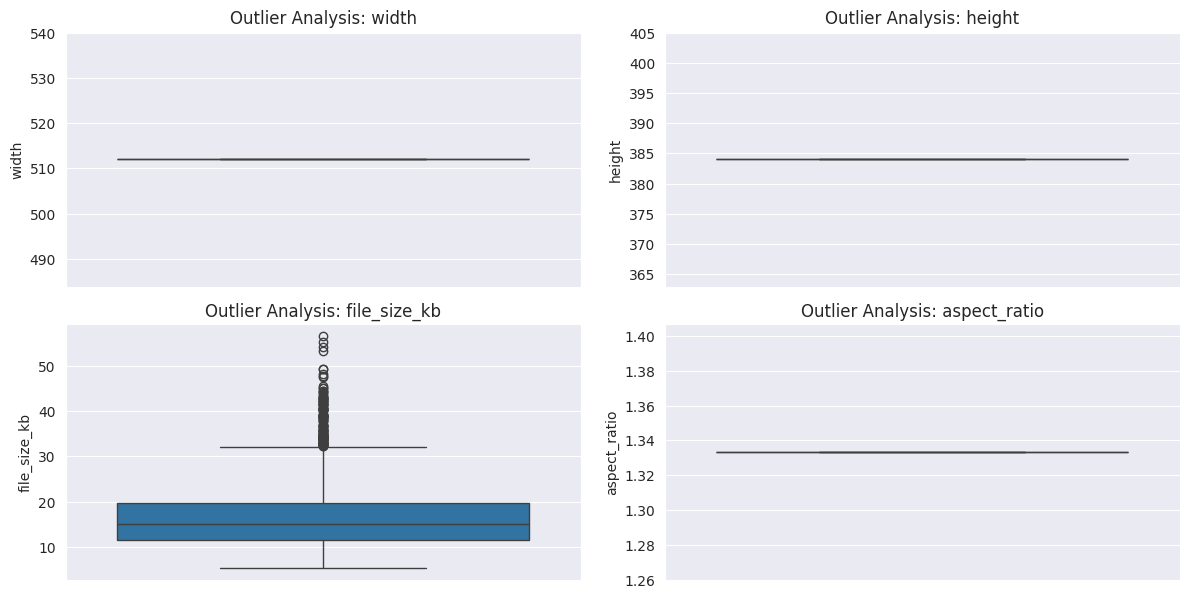

In [7]:
plt.figure(figsize=(12, 6))

for i, column in enumerate(outlier_columns):

    plt.subplot(2, 2, i + 1)

    sns.boxplot(y=df_images[column])

    plt.title(f"Outlier Analysis: {column}")

plt.tight_layout()
plt.show()

### Outlier Analysis Observations

The Interquartile Range (IQR) method is used to identify
unusual image properties.

Image dimensions, file sizes, and aspect ratios are
analyzed to understand variations in the dataset.

Detected outliers are not automatically removed because
unusual image properties do not necessarily indicate
incorrect or irrelevant images.

## 6. Data Preprocessing and Transformation

Image preprocessing is an important step before training
deep learning models.

The following transformations are applied:

1. Image resizing to 224 × 224 pixels.
2. Conversion from BGR to RGB color format.
3. Normalization of pixel values between 0 and 1.

These transformations provide a consistent input format
for deep learning architectures.

Original Image Path: /content/trashnet_extracted/dataset-resized/cardboard/cardboard272.jpg
Processed Image Shape: (224, 224, 3)
Minimum Pixel Value: 0.011764706
Maximum Pixel Value: 1.0


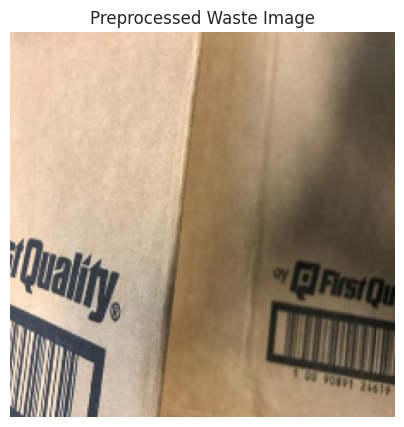

In [8]:
# Define target image dimensions
IMG_SIZE = 224

def preprocess_image(image_path):

    # Read image
    img = cv2.imread(image_path)

    if img is None:
        return None

    # Convert BGR to RGB
    img = cv2.cvtColor(
        img,
        cv2.COLOR_BGR2RGB
    )

    # Resize image
    img = cv2.resize(
        img,
        (IMG_SIZE, IMG_SIZE)
    )

    # Normalize pixel values
    img = img.astype("float32") / 255.0

    return img


# Test preprocessing on one image
sample_path = df_images.iloc[0]["image_path"]

processed_image = preprocess_image(sample_path)

print("Original Image Path:", sample_path)

print("Processed Image Shape:", processed_image.shape)

print("Minimum Pixel Value:", processed_image.min())

print("Maximum Pixel Value:", processed_image.max())


# Display processed image
plt.figure(figsize=(5, 5))

plt.imshow(processed_image)

plt.title("Preprocessed Waste Image")

plt.axis("off")

plt.show()

## 7. Feature Engineering

Feature engineering involves extracting meaningful
information from raw data.

In this project, basic visual features are extracted
from waste images, including RGB color information
and brightness.

These features help us understand the visual
characteristics of different waste categories.

In [9]:
# Function to extract basic image features

def extract_features(image_path):

    img = cv2.imread(image_path)

    if img is None:
        return None

    # Convert BGR to RGB
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Resize image
    img = cv2.resize(img, (224, 224))

    # Extract average RGB values
    mean_red = np.mean(img[:, :, 0])
    mean_green = np.mean(img[:, :, 1])
    mean_blue = np.mean(img[:, :, 2])

    # Calculate average brightness
    brightness = np.mean(
        cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    )

    return {
        "mean_red": mean_red,
        "mean_green": mean_green,
        "mean_blue": mean_blue,
        "brightness": brightness
    }


# Extract features from all images

feature_records = []

for _, row in df_images.iterrows():

    features = extract_features(row["image_path"])

    if features is not None:

        features["category"] = row["category"]

        feature_records.append(features)


# Create feature DataFrame

df_features = pd.DataFrame(feature_records)

print("Extracted Features:")
display(df_features.head())

print("\nFeature Dataset Shape:")
print(df_features.shape)

Extracted Features:


,mean_red,mean_green,mean_blue,brightness,category
0,160.846600,140.254783,116.325295,143.716059,cardboard
1,145.392658,135.726901,129.724430,137.964625,cardboard
2,179.923908,180.280174,184.237364,180.666315,cardboard
3,197.290557,75.069017,80.404377,112.195811,cardboard
4,152.185288,136.535834,116.515446,138.943638,cardboard



Feature Dataset Shape:
(2527, 5)


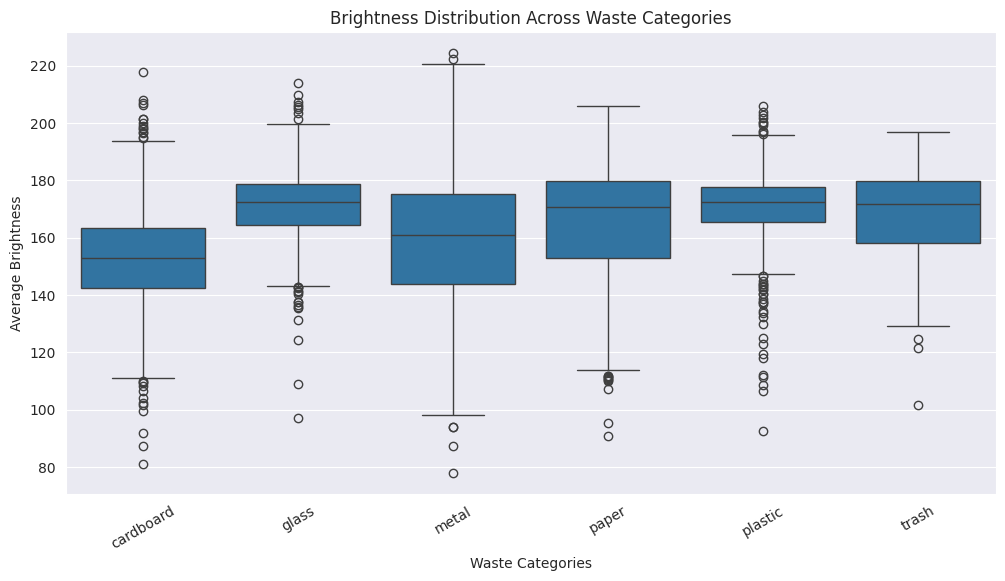

In [10]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_features,
    x="category",
    y="brightness"
)

plt.title("Brightness Distribution Across Waste Categories")

plt.xlabel("Waste Categories")

plt.ylabel("Average Brightness")

plt.xticks(rotation=30)

plt.show()

## 8. Feature Selection

Feature selection helps identify the most relevant
features for a machine learning task.

In this project, RGB values and brightness are analyzed
to understand their relationship and usefulness.

However, since the proposed architecture uses CNN-based
image processing, the model will automatically learn
important visual features from the images.

Therefore, manually extracted color features are mainly
used for exploratory analysis rather than replacing
CNN-based feature extraction.

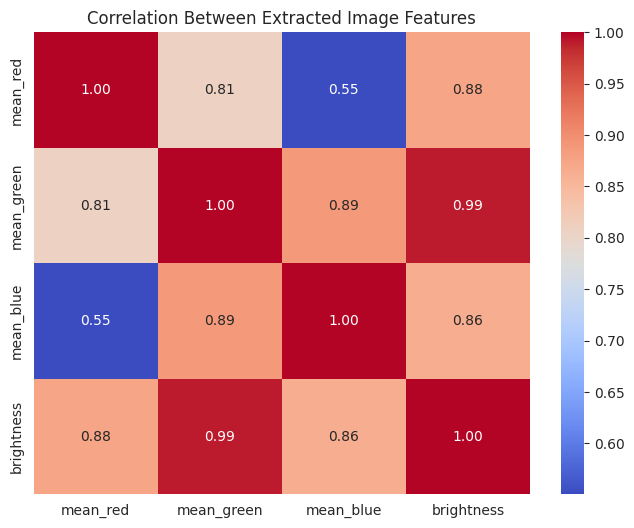

In [11]:
# Select numerical features

selected_features = [
    "mean_red",
    "mean_green",
    "mean_blue",
    "brightness"
]

# Calculate correlation
correlation_matrix = df_features[
    selected_features
].corr()

# Display correlation heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Extracted Image Features")

plt.show()

## 9. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand
the structure, distribution, and visual characteristics
of the dataset.

Different visualizations are used to identify class
imbalance, image dimensions, file sizes, and color
distributions.

,Image Count,Percentage
category,,
paper,594,23.506134
glass,501,19.825880
plastic,482,19.074001
metal,410,16.224772
cardboard,403,15.947764
trash,137,5.421448


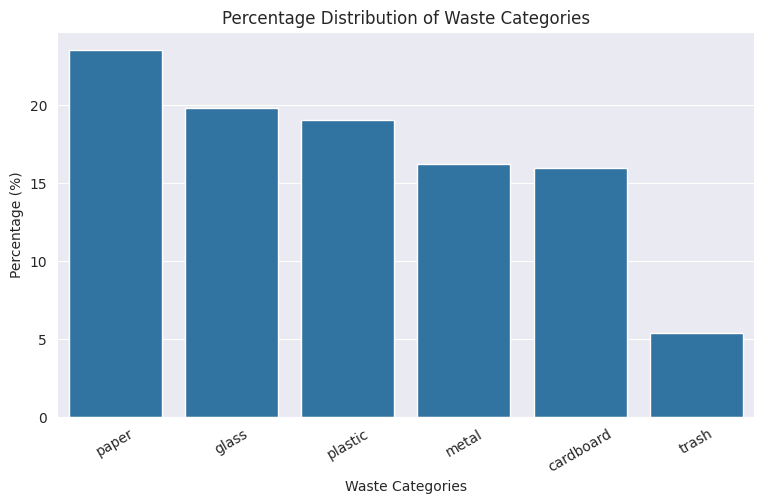

In [12]:
# Calculate class distribution
class_distribution = df_images["category"].value_counts()

# Calculate percentage
class_percentage = (
    class_distribution / len(df_images)
) * 100

# Create summary
class_summary = pd.DataFrame({
    "Image Count": class_distribution,
    "Percentage": class_percentage
})

display(class_summary)

# Visualize class percentages
plt.figure(figsize=(9, 5))

sns.barplot(
    x=class_summary.index,
    y=class_summary["Percentage"]
)

plt.title("Percentage Distribution of Waste Categories")

plt.xlabel("Waste Categories")

plt.ylabel("Percentage (%)")

plt.xticks(rotation=30)

plt.show()

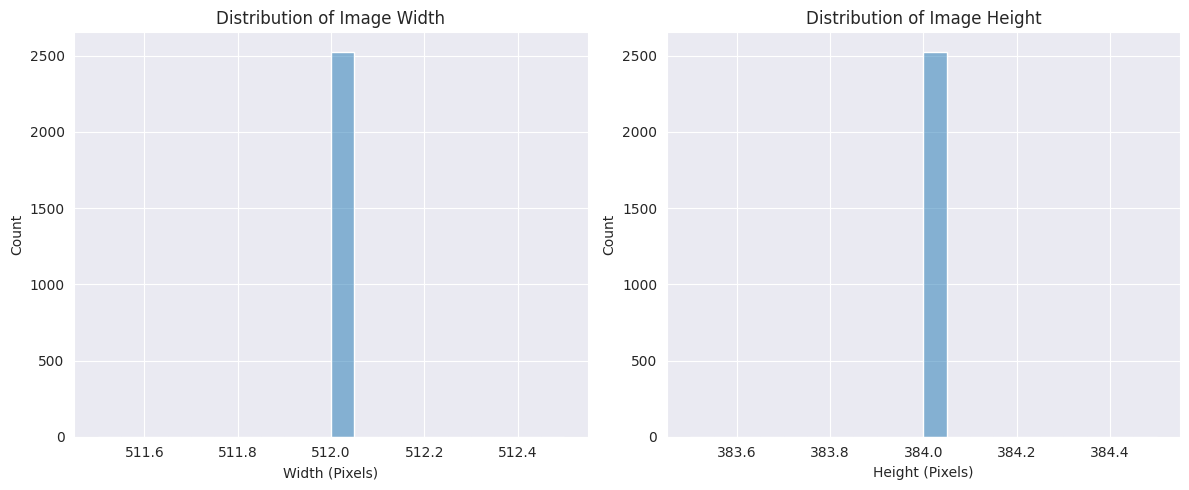

In [13]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

sns.histplot(
    df_images["width"],
    bins=20,
    kde=True
)

plt.title("Distribution of Image Width")

plt.xlabel("Width (Pixels)")


plt.subplot(1, 2, 2)

sns.histplot(
    df_images["height"],
    bins=20,
    kde=True
)

plt.title("Distribution of Image Height")

plt.xlabel("Height (Pixels)")


plt.tight_layout()

plt.show()

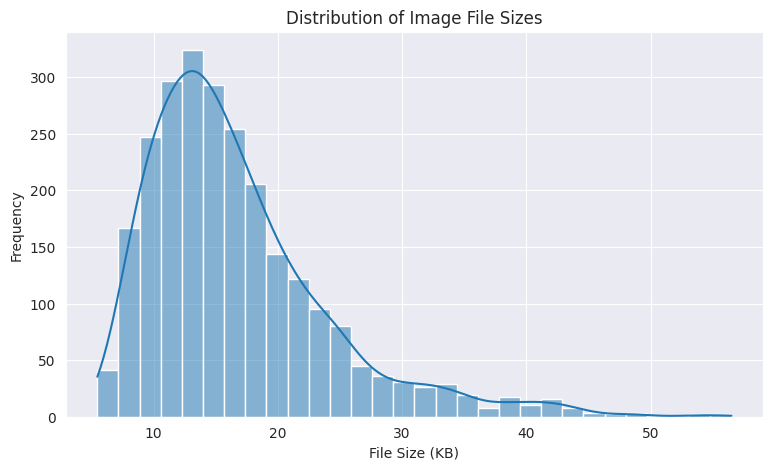

In [14]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df_images,
    x="file_size_kb",
    bins=30,
    kde=True
)

plt.title("Distribution of Image File Sizes")

plt.xlabel("File Size (KB)")

plt.ylabel("Frequency")

plt.show()

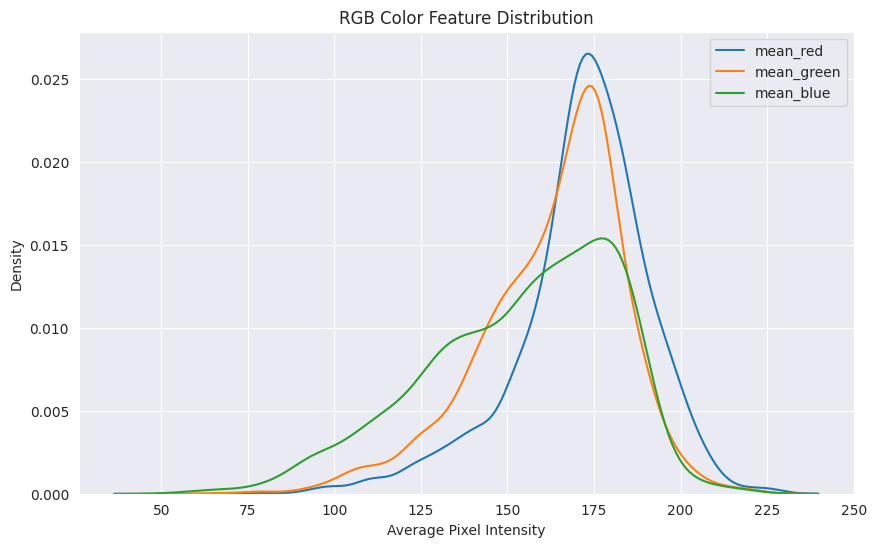

In [15]:
plt.figure(figsize=(10, 6))

color_columns = [
    "mean_red",
    "mean_green",
    "mean_blue"
]

for column in color_columns:

    sns.kdeplot(
        data=df_features,
        x=column,
        label=column
    )

plt.title("RGB Color Feature Distribution")

plt.xlabel("Average Pixel Intensity")

plt.ylabel("Density")

plt.legend()

plt.show()

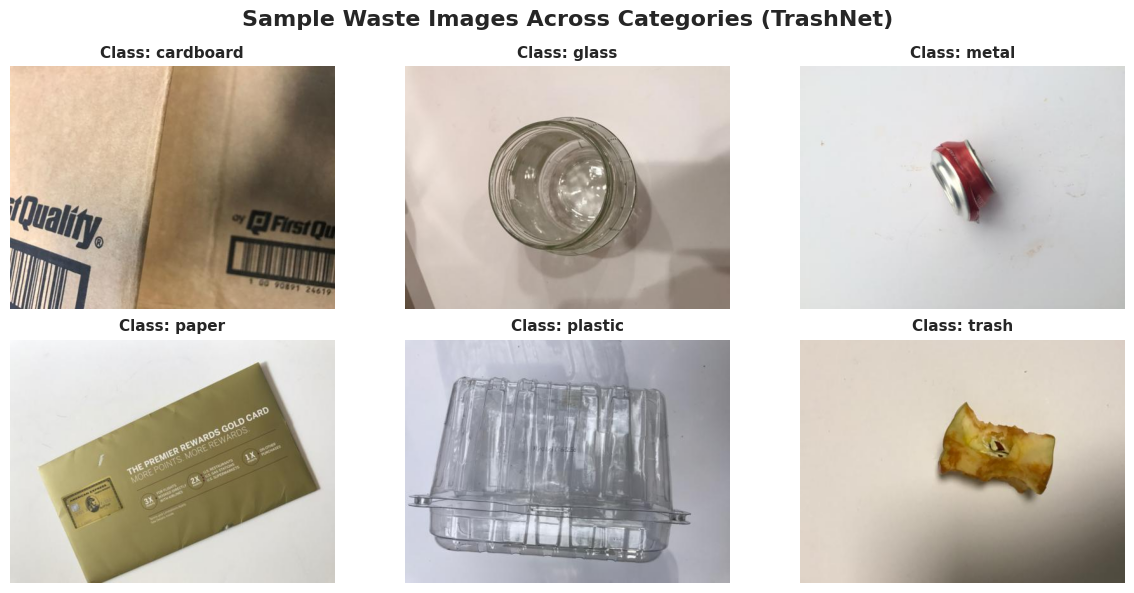

In [16]:
# Visualizing sample images from each waste category
plt.figure(figsize=(12, 6))
for i, category in enumerate(categories):
    folder_path = os.path.join(dataset_path, category)
    if os.path.exists(folder_path) and len(os.listdir(folder_path)) > 0:
        sample_img_name = os.listdir(folder_path)[0]
        img_full_path = os.path.join(folder_path, sample_img_name)

        img = cv2.imread(img_full_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        plt.subplot(2, 3, i + 1)
        plt.imshow(img)
        plt.title(f"Class: {category}", fontsize=11, fontweight='bold')
        plt.axis('off')

plt.suptitle('Sample Waste Images Across Categories (TrashNet)', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

## 10. Key Observations and Insights

Based on the dataset analysis and exploratory data
analysis, the following observations were identified:

1. **Class Imbalance:** The dataset contains six waste
categories with different numbers of images. The Trash
category has fewer samples compared to other categories.

2. **Data Quality:** Image integrity, missing values,
and duplicate images were examined to assess dataset quality.

3. **Image Properties:** Image dimensions, aspect ratios,
and file sizes were analyzed. These properties show
variations in the dataset.

4. **Visual Characteristics:** RGB color values and
brightness were analyzed to understand the visual
differences between waste categories.

5. **Preprocessing Requirements:** Images are resized
to 224 × 224 pixels and normalized between 0 and 1
to provide consistent input for deep learning models.

6. **Feature Engineering:** Basic visual features were
extracted for exploratory analysis. CNN-based models
will automatically learn more complex visual features.

7. **Model Development Considerations:** Due to class
imbalance and visual similarities between waste
categories, evaluation should include precision,
recall, macro F1-score, and confusion matrix.

### Conclusion

The first phase of the project successfully establishes
the dataset acquisition, data cleaning, preprocessing,
feature engineering, and exploratory data analysis
workflow.

The findings from this phase will guide the next stage
of developing and evaluating the proposed hybrid
CNN-RNN-GRU architecture.

# Part 2: Model Development, Optimization, Evaluation & Complete ML Pipeline

## 9. Deduplication and Stratified Data Splitting (80% / 10% / 10%)

To prevent data leakage across partitions, exact duplicate images identified via MD5 hashing in Part 1 are removed prior to splitting. The cleaned dataset is then partitioned using stratified sampling into:
- **Training Set (80%)**: Used for model weight updates and data augmentation.
- **Validation Set (10%)**: Used for early stopping, learning rate scheduling, and hyperparameter tuning.
- **Hold-out Test Set (10%)**: Strictly quarantined until final model evaluation.

In [17]:
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    accuracy_score,
    precision_score,
    recall_score
)

# Reproducibility seeds
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

# 1. Remove exact duplicate images to prevent train/val/test leakage
df_clean = df_images.drop_duplicates(subset=["image_hash"]).reset_index(drop=True)
print(f"Images before deduplication: {len(df_images)} | After deduplication: {len(df_clean)}")

# 2. Map categories to integer indices
categories = ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
label_to_idx = {cat: idx for idx, cat in enumerate(categories)}
idx_to_label = {idx: cat for idx, cat in enumerate(categories)}
df_clean["label"] = df_clean["category"].map(label_to_idx)

# 3. Stratified 80% Train / 10% Validation / 10% Test Split
train_df, temp_df = train_test_split(
    df_clean,
    test_size=0.20,
    stratify=df_clean["label"],
    random_state=SEED
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=SEED
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

split_summary = pd.DataFrame({
    "Train (80%)": train_df["category"].value_counts().reindex(categories),
    "Validation (10%)": val_df["category"].value_counts().reindex(categories),
    "Test (10%)": test_df["category"].value_counts().reindex(categories),
})
split_summary.loc["TOTAL"] = split_summary.sum()
display(split_summary)

TensorFlow Version: 2.21.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Images before deduplication: 2527 | After deduplication: 2524


,Train (80%),Validation (10%),Test (10%)
category,,,
cardboard,322,40,41
glass,401,50,50
metal,327,41,41
paper,475,59,60
plastic,384,48,48
trash,110,14,13
TOTAL,2019,252,253


## 10. High-Performance TensorFlow Data Pipeline & Data Augmentation

To address geometric variance and mitigate severe class imbalance (where `trash` represents ~5.4% of samples compared to ~23.5% for `paper`), we construct a `tf.data.Dataset` pipeline:
- **Standardization**: All images are decoded in RGB, resized to `224 × 224 × 3`, and normalized to `[0, 1]`.
- **Training Augmentation**: Random horizontal/vertical flips, random affine rotations (`±20°`), random zoom (`±15%`), and width/height translations (`±10%`) are applied exclusively to the training split.

In [18]:
IMG_SIZE = 224
NUM_CLASSES = len(categories)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# Data augmentation block (active only during training)
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical", seed=SEED),
    layers.RandomRotation(0.056, seed=SEED),      # ~ +/- 20 degrees (20/360 = 0.056)
    layers.RandomZoom(0.15, seed=SEED),
    layers.RandomTranslation(0.10, 0.10, seed=SEED),
], name="data_augmentation")

def load_and_preprocess_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32) / 255.0
    label_one_hot = tf.one_hot(label, depth=NUM_CLASSES)
    return img, label_one_hot

def create_dataset(df, batch_size=BATCH_SIZE, is_training=False):
    ds = tf.data.Dataset.from_tensor_slices((df["image_path"].values, df["label"].values))
    ds = ds.map(load_and_preprocess_image, num_parallel_calls=AUTOTUNE)
    ds = ds.cache()
    if is_training:
        ds = ds.shuffle(buffer_size=len(df), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(batch_size)
    if is_training:
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=AUTOTUNE)
    ds = ds.prefetch(AUTOTUNE)
    return ds

train_ds = create_dataset(train_df, batch_size=BATCH_SIZE, is_training=True)
val_ds = create_dataset(val_df, batch_size=BATCH_SIZE, is_training=False)
test_ds = create_dataset(test_df, batch_size=BATCH_SIZE, is_training=False)

# Compute balanced class weights to address minority class ('trash') skewness
class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_df["label"]),
    y=train_df["label"]
)
class_weight_dict = {i: float(w) for i, w in enumerate(class_weights_array)}
print("Computed Class Weights:", {idx_to_label[k]: round(v, 3) for k, v in class_weight_dict.items()})

Computed Class Weights: {'cardboard': 1.045, 'glass': 0.839, 'metal': 1.029, 'paper': 0.708, 'plastic': 0.876, 'trash': 3.059}


## 11. Model Selection and Architecture Implementation

Per the project proposal, we implement and benchmark two architectures under identical preprocessing and evaluation protocols:
1. **Baseline Model — 3-Block Conv2D CNN**: Three sequential `Conv2D` + `BatchNormalization` + `MaxPooling2D` blocks (32, 64, 128 filters) followed by `GlobalAveragePooling2D`, `Dropout`, and a 6-class `Softmax` head.
2. **Proposed Candidate Model — Hybrid CNN-RNN-GRU Architecture**: Uses stacked `Conv2D` + `MaxPooling2D` layers to extract hierarchical spatial feature maps (`7 × 7 × 128`), reshapes the spatial grid into a sequence of `49` spatial tokens (`49 × 128`), and processes them through stacked **GRU (256 units)** and **LSTM (128 units)** layers with `Dropout` regularization to capture intra-object spatial-sequential dependencies before final classification.

In [19]:
def build_baseline_cnn(input_shape=(IMG_SIZE, IMG_SIZE, 3), num_classes=NUM_CLASSES, dropout_rate=0.3, lr=1e-3):
    inputs = layers.Input(shape=input_shape)

    # Block 1
    x = layers.Conv2D(32, (3, 3), padding="same", activation="relu")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # Block 2
    x = layers.Conv2D(64, (3, 3), padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # Block 3
    x = layers.Conv2D(128, (3, 3), padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout_rate)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(dropout_rate)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = models.Model(inputs, outputs, name="Baseline_3Block_CNN")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


def build_hybrid_cnn_rnn_gru(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    num_classes=NUM_CLASSES,
    gru_units=256,
    lstm_units=128,
    dropout_rate=0.3,
    lr=1e-3
):
    inputs = layers.Input(shape=input_shape)

    # Hierarchical CNN Spatial Feature Extractor
    x = layers.Conv2D(32, (3, 3), padding="same", activation="relu")(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)   # 112x112x32

    x = layers.Conv2D(64, (3, 3), padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)   # 56x56x64

    x = layers.Conv2D(128, (3, 3), padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((4, 4))(x)   # 14x14x128

    x = layers.Conv2D(128, (3, 3), padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)   # 7x7x128

    # Project 2D spatial grid (7x7x128) into sequential feature steps (49x128)
    _, h, w, c = x.shape
    x = layers.Reshape((h * w, c))(x)

    # Recurrent Sequence Modeling (Stacked GRU + LSTM)
    x = layers.GRU(gru_units, return_sequences=True)(x)
    x = layers.Dropout(dropout_rate)(x)
    x = layers.GRU(gru_units, return_sequences=True)(x)
    x = layers.Dropout(dropout_rate)(x)
    x = layers.LSTM(lstm_units, return_sequences=False)(x)
    x = layers.Dropout(dropout_rate)(x)

    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = models.Model(inputs, outputs, name="Hybrid_CNN_RNN_GRU")
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model

baseline_model = build_baseline_cnn()
hybrid_model = build_hybrid_cnn_rnn_gru()

print("--- Baseline CNN Summary ---")
baseline_model.summary()
print("\n--- Hybrid CNN-RNN-GRU Summary ---")
hybrid_model.summary()

--- Baseline CNN Summary ---


Model: "Baseline_3Block_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,430 (435.27 KB)

 Trainable params: 110,982 (433.52 KB)

 Non-trainable params: 448 (1.75 KB)

... (2 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 14, 14, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 14, 14, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 49, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 49, 256)        │       296,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 49, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 49, 256)        │       394,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 49, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │       197,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,131,334 (4.32 MB)

 Trainable params: 1,130,630 (4.31 MB)

 Non-trainable params: 704 (2.75 KB)

## 12. Model Training, Hyperparameter Tuning, and Class-Imbalance Optimization

We execute a structured experimental progression using `EarlyStopping` (monitoring `val_loss`) and `ReduceLROnPlateau`:
1. **Experiment 1 — Baseline 3-Block CNN** (`lr=1e-3`, `dropout=0.3`, unweighted loss)
2. **Experiment 2 — Proposed Hybrid CNN-RNN-GRU (Default Config)** (`lr=1e-3`, `gru_units=256`, `lstm_units=128`, `dropout=0.3`, unweighted loss)
3. **Experiment 3 — Hyperparameter-Tuned Hybrid CNN-RNN-GRU** (`lr=5e-4`, `dropout=0.4`, finer learning rate + stronger regularization)
4. **Experiment 4 — Optimized Hybrid CNN-RNN-GRU with Cost-Sensitive Class Weights** (`lr=5e-4`, `dropout=0.4`, balanced `class_weight` to boost minority class `trash` recall and Macro-F1)

In [21]:
def get_callbacks(checkpoint_path, patience=6):
    return [
        callbacks.EarlyStopping(
            monitor="val_loss",
            patience=patience,
            restore_best_weights=True,
            verbose=1
        ),
        callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=1e-6,
            verbose=1
        ),
        callbacks.ModelCheckpoint(
            filepath=checkpoint_path,
            monitor="val_loss",
            save_best_only=True,
            verbose=0
        )
    ]

def evaluate_on_dataset(model, dataset, df_eval):
    y_true = df_eval["label"].values
    # Warm-up pass for accurate latency timing
    for batch_x, _ in dataset.take(1):
        _ = model.predict(batch_x, verbose=0)

    start_time = time.perf_counter()
    y_probs = model.predict(dataset, verbose=0)
    elapsed_ms = (time.perf_counter() - start_time) * 1000.0
    latency_ms_per_img = elapsed_ms / len(df_eval)

    y_pred = np.argmax(y_probs, axis=1)
    acc = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro")
    macro_prec = precision_score(y_true, y_pred, average="macro", zero_division=0)
    macro_rec = recall_score(y_true, y_pred, average="macro", zero_division=0)

    return {
        "accuracy": acc,
        "macro_f1": macro_f1,
        "macro_precision": macro_prec,
        "macro_recall": macro_rec,
        "latency_ms": latency_ms_per_img,
        "y_true": y_true,
        "y_pred": y_pred,
        "y_probs": y_probs
    }

EPOCHS = 30
histories = {}
val_results = {}
test_results = {}
trained_models = {}

# --- Run 1: Baseline 3-Block CNN ---
print("\n[1/4] Training Baseline 3-Block CNN...")
m1 = build_baseline_cnn(dropout_rate=0.3, lr=1e-3)
histories["Baseline CNN"] = m1.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=get_callbacks("best_baseline_cnn.keras"),
    verbose=1
)
trained_models["Baseline CNN"] = m1
val_results["Baseline CNN"] = evaluate_on_dataset(m1, val_ds, val_df)
test_results["Baseline CNN"] = evaluate_on_dataset(m1, test_ds, test_df)

# --- Run 2: Hybrid CNN-RNN-GRU (Config A: lr=1e-3, dropout=0.3) ---
print("\n[2/4] Training Hybrid CNN-RNN-GRU (Default Config)...")
m2 = build_hybrid_cnn_rnn_gru(gru_units=256, lstm_units=128, dropout_rate=0.3, lr=1e-3)
histories["Hybrid CNN-RNN-GRU (Base)"] = m2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=get_callbacks("best_hybrid_base.keras"),
    verbose=1
)
trained_models["Hybrid CNN-RNN-GRU (Base)"] = m2
val_results["Hybrid CNN-RNN-GRU (Base)"] = evaluate_on_dataset(m2, val_ds, val_df)
test_results["Hybrid CNN-RNN-GRU (Base)"] = evaluate_on_dataset(m2, test_ds, test_df)

# --- Run 3: Hyperparameter-Tuned Hybrid CNN-RNN-GRU (Config B: lr=5e-4, dropout=0.4) ---
print("\n[3/4] Training Tuned Hybrid CNN-RNN-GRU (lr=5e-4, dropout=0.4)...")
m3 = build_hybrid_cnn_rnn_gru(gru_units=256, lstm_units=128, dropout_rate=0.4, lr=5e-4)
histories["Hybrid CNN-RNN-GRU (Tuned)"] = m3.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=get_callbacks("best_hybrid_tuned.keras"),
    verbose=1
)
trained_models["Hybrid CNN-RNN-GRU (Tuned)"] = m3
val_results["Hybrid CNN-RNN-GRU (Tuned)"] = evaluate_on_dataset(m3, val_ds, val_df)
test_results["Hybrid CNN-RNN-GRU (Tuned)"] = evaluate_on_dataset(m3, test_ds, test_df)

# --- Run 4: Optimized Hybrid CNN-RNN-GRU + Balanced Class Weights ---
print("\n[4/4] Training Optimized Hybrid CNN-RNN-GRU + Class Weights...")
m4 = build_hybrid_cnn_rnn_gru(gru_units=256, lstm_units=128, dropout_rate=0.4, lr=5e-4)
histories["Hybrid CNN-RNN-GRU (Weighted)"] = m4.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weight_dict,
    callbacks=get_callbacks("best_hybrid_weighted.keras"),
    verbose=1
)
trained_models["Hybrid CNN-RNN-GRU (Weighted)"] = m4
val_results["Hybrid CNN-RNN-GRU (Weighted)"] = evaluate_on_dataset(m4, val_ds, val_df)
test_results["Hybrid CNN-RNN-GRU (Weighted)"] = evaluate_on_dataset(m4, test_ds, test_df)


[1/4] Training Baseline 3-Block CNN...
Epoch 1/30
64/64 ━━━━━━━━━━━━━━━━━━━━ 41s 505ms/step - accuracy: 0.4433 - loss: 1.4478 - val_accuracy: 0.2341 - val_loss: 1.7893 - learning_rate: 0.0010
Epoch 2/30
64/64 ━━━━━━━━━━━━━━━━━━━━ 29s 439ms/step - accuracy: 0.5161 - loss: 1.2872 - val_accuracy: 0.2857 - val_loss: 1.8280 - learning_rate: 0.0010
Epoch 3/30
64/64 ━━━━━━━━━━━━━━━━━━━━ 41s 430ms/step - accuracy: 0.5300 - loss: 1.2235 - val_accuracy: 0.2222 - val_loss: 2.0357 - learning_rate: 0.0010
Epoch 4/30
63/64 ━━━━━━━━━━━━━━━━━━━━ 0s 425ms/step - accuracy: 0.5695 - loss: 1.1395
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
64/64 ━━━━━━━━━━━━━━━━━━━━ 40s 423ms/step - accuracy: 0.5572 - loss: 1.1636 - val_accuracy: 0.2024 - val_loss: 1.9092 - learning_rate: 0.0010
Epoch 5/30
64/64 ━━━━━━━━━━━━━━━━━━━━ 28s 434ms/step - accuracy: 0.5815 - loss: 1.1167 - val_accuracy: 0.3056 - val_loss: 1.7186 - learning_rate: 5.0000e-04
Epoch 6/30
64/64 ━━━━━━━━━━━━━━━━━━━━ 28

## 13. Model Comparison, Evaluation Metrics, and Results Visualization

In accordance with the project success criteria, models are evaluated on **Macro-Averaged F1-Score** (primary metric to avoid majority-class bias), alongside overall **Accuracy**, **Macro Precision**, **Macro Recall**, **Confusion Matrix**, and **Inference Latency (ms/frame)**.

--- Model Benchmarking Summary ---


,Model,Val Accuracy (%),Val Macro-F1 (%),Test Accuracy (%),Test Macro-F1 (%),Test Precision (%),Test Recall (%),Latency (ms/img)
0,Baseline CNN,73.41,68.42,74.70,70.49,79.44,68.57,13.63
1,Hybrid CNN-RNN-GRU (Base),78.57,75.76,82.21,79.53,80.01,80.79,3.08
2,Hybrid CNN-RNN-GRU (Tuned),81.35,80.05,83.40,82.60,84.02,82.71,1.20
3,Hybrid CNN-RNN-GRU (Weighted),76.98,75.35,81.42,79.01,78.41,80.06,1.01



Selected Final Model (Best Validation Macro-F1): Hybrid CNN-RNN-GRU (Tuned)
Hold-Out Test Accuracy: 83.40% | Test Macro-F1: 82.60%


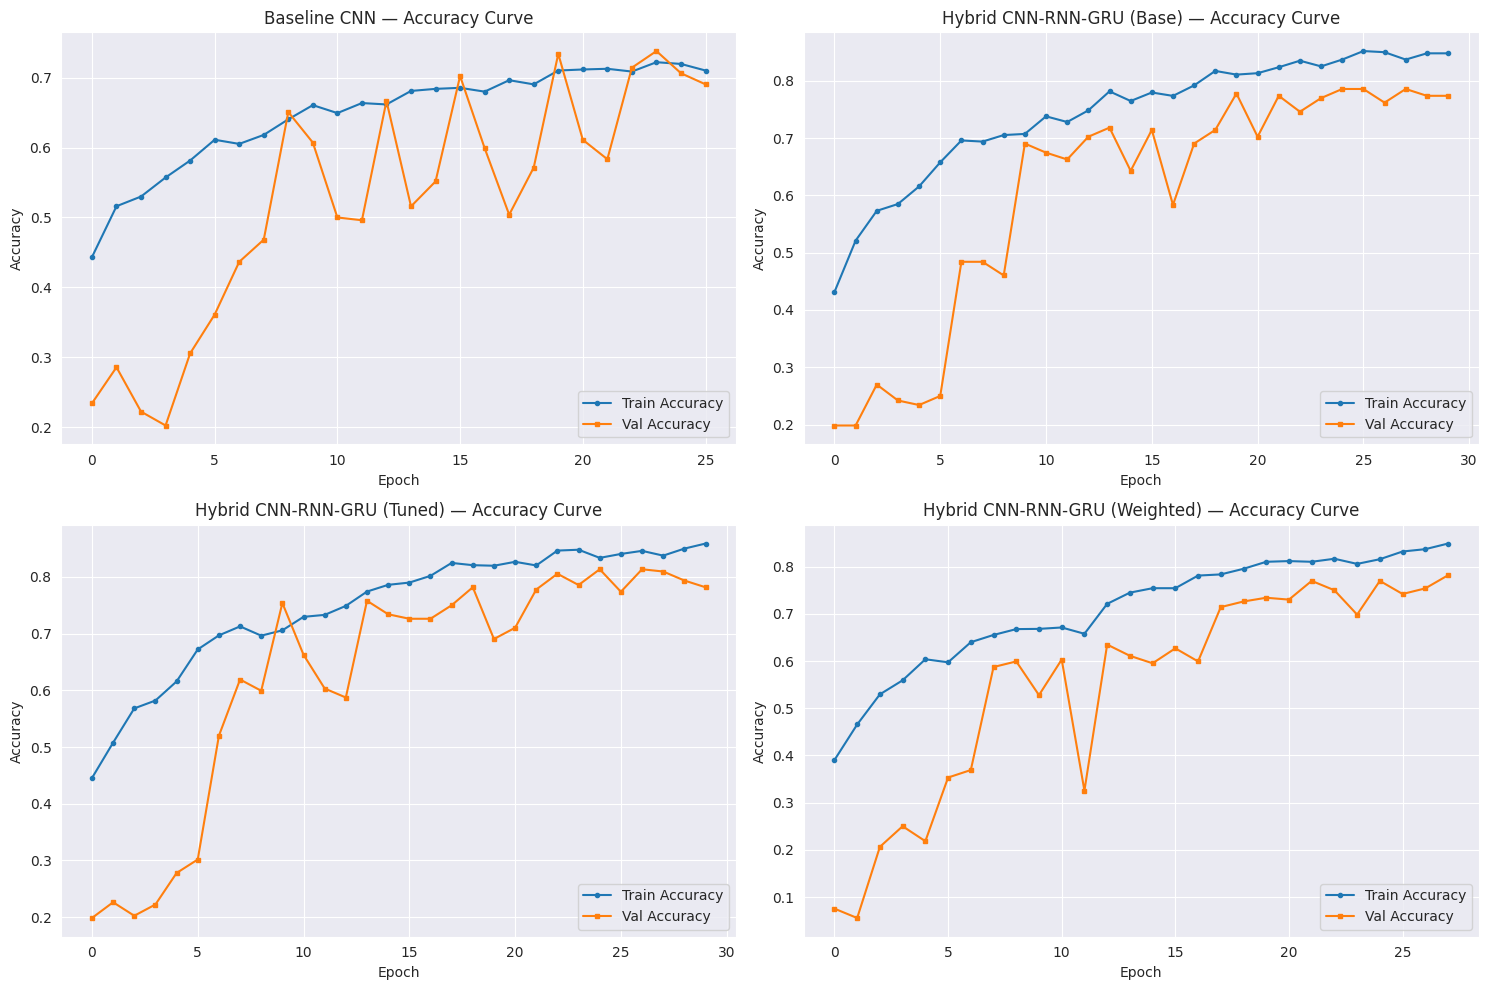

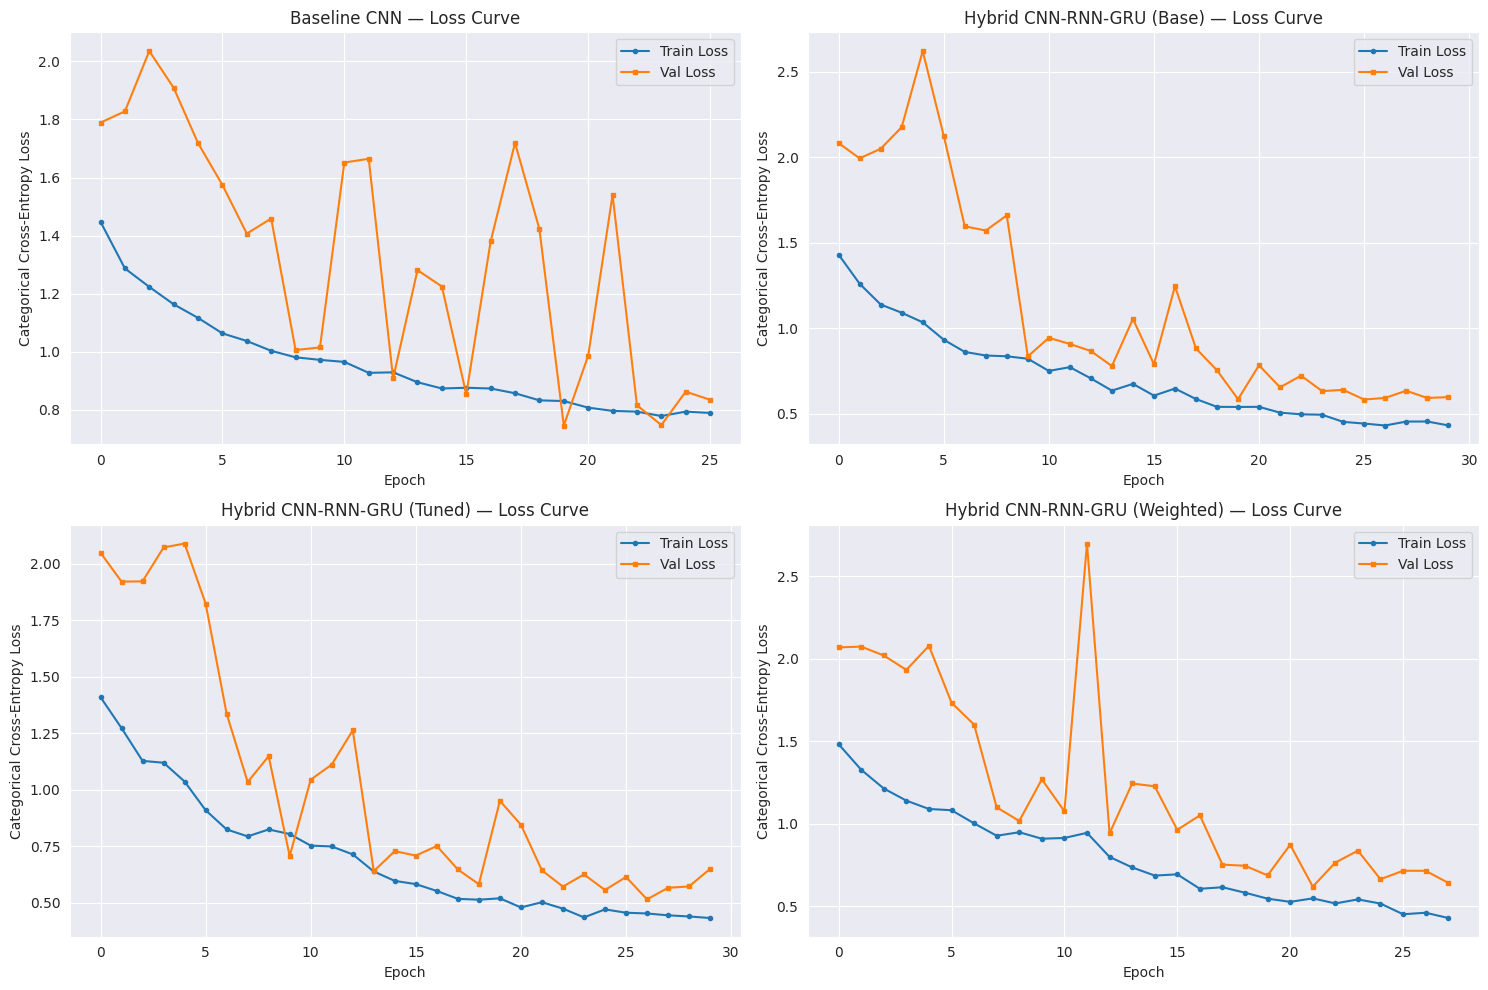

In [22]:
# Build comprehensive comparison table
comparison_rows = []
for name in trained_models.keys():
    vr = val_results[name]
    tr = test_results[name]
    comparison_rows.append({
        "Model": name,
        "Val Accuracy (%)": round(vr["accuracy"] * 100, 2),
        "Val Macro-F1 (%)": round(vr["macro_f1"] * 100, 2),
        "Test Accuracy (%)": round(tr["accuracy"] * 100, 2),
        "Test Macro-F1 (%)": round(tr["macro_f1"] * 100, 2),
        "Test Precision (%)": round(tr["macro_precision"] * 100, 2),
        "Test Recall (%)": round(tr["macro_recall"] * 100, 2),
        "Latency (ms/img)": round(tr["latency_ms"], 2)
    })

df_comparison = pd.DataFrame(comparison_rows)
print("--- Model Benchmarking Summary ---")
display(df_comparison)

# Select best model based on Validation Macro-F1 (no test-set leakage)
best_model_name = max(val_results.keys(), key=lambda k: val_results[k]["macro_f1"])
best_model = trained_models[best_model_name]
best_test = test_results[best_model_name]
print(f"\nSelected Final Model (Best Validation Macro-F1): {best_model_name}")
print(f"Hold-Out Test Accuracy: {best_test['accuracy']*100:.2f}% | Test Macro-F1: {best_test['macro_f1']*100:.2f}%")

# Plot 1: Training & Validation Accuracy and Loss Curves
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for idx, (name, hist) in enumerate(histories.items()):
    ax = axes[idx]
    ax.plot(hist.history["accuracy"], label="Train Accuracy", marker="o", markersize=3)
    ax.plot(hist.history["val_accuracy"], label="Val Accuracy", marker="s", markersize=3)
    ax.set_title(f"{name} — Accuracy Curve")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Accuracy")
    ax.legend(loc="lower right")
    ax.grid(True)

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for idx, (name, hist) in enumerate(histories.items()):
    ax = axes[idx]
    ax.plot(hist.history["loss"], label="Train Loss", marker="o", markersize=3)
    ax.plot(hist.history["val_loss"], label="Val Loss", marker="s", markersize=3)
    ax.set_title(f"{name} — Loss Curve")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Categorical Cross-Entropy Loss")
    ax.legend(loc="upper right")
    ax.grid(True)

plt.tight_layout()
plt.show()

--- Per-Class Test Performance (Hybrid CNN-RNN-GRU (Tuned)) ---
              precision    recall  f1-score   support

   cardboard     0.9024    0.9024    0.9024        41
       glass     0.9091    0.6000    0.7229        50
       metal     0.7609    0.8537    0.8046        41
       paper     0.8852    0.9000    0.8926        60
     plastic     0.7500    0.9375    0.8333        48
       trash     0.8333    0.7692    0.8000        13

    accuracy                         0.8340       253
   macro avg     0.8402    0.8271    0.8260       253
weighted avg     0.8443    0.8340    0.8304       253



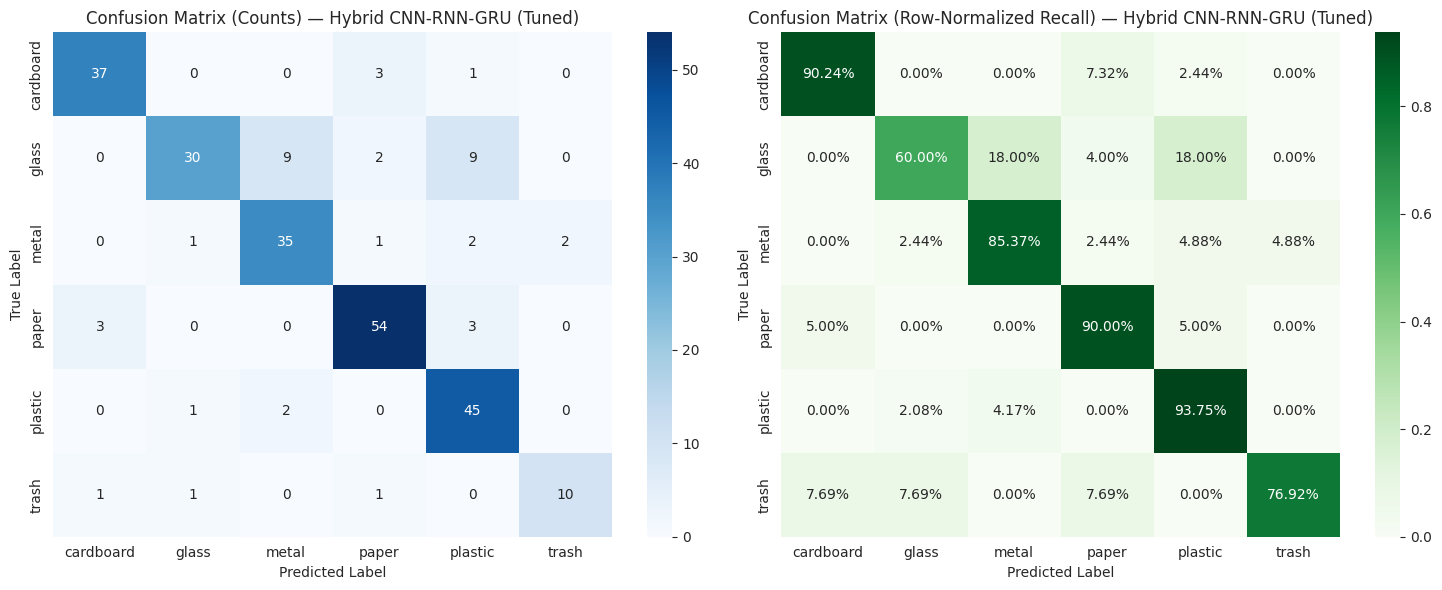

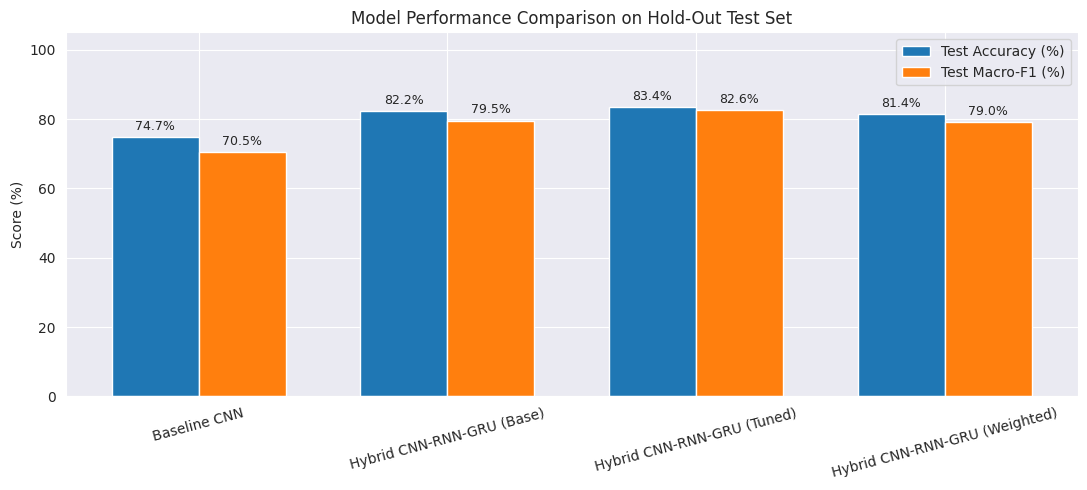

In [23]:
# Per-Class Classification Report for the Final Selected Model
print(f"--- Per-Class Test Performance ({best_model_name}) ---")
print(classification_report(
    best_test["y_true"],
    best_test["y_pred"],
    target_names=categories,
    digits=4
))

# Plot 2: Confusion Matrix (Counts & Normalized)
cm = confusion_matrix(best_test["y_true"], best_test["y_pred"])
cm_norm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=categories, yticklabels=categories, ax=axes[0])
axes[0].set_title(f"Confusion Matrix (Counts) — {best_model_name}")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")

sns.heatmap(cm_norm, annot=True, fmt=".2%", cmap="Greens", xticklabels=categories, yticklabels=categories, ax=axes[1])
axes[1].set_title(f"Confusion Matrix (Row-Normalized Recall) — {best_model_name}")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")

plt.tight_layout()
plt.show()

# Plot 3: Model Comparison Bar Chart (Test Accuracy vs Test Macro-F1)
x = np.arange(len(df_comparison))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 5))
rects1 = ax.bar(x - width/2, df_comparison["Test Accuracy (%)"], width, label="Test Accuracy (%)")
rects2 = ax.bar(x + width/2, df_comparison["Test Macro-F1 (%)"], width, label="Test Macro-F1 (%)")

ax.set_ylabel("Score (%)")
ax.set_title("Model Performance Comparison on Hold-Out Test Set")
ax.set_xticks(x)
ax.set_xticklabels(df_comparison["Model"], rotation=15)
ax.set_ylim(0, 105)
ax.legend()

for rect in rects1 + rects2:
    h = rect.get_height()
    ax.annotate(f"{h:.1f}%", xy=(rect.get_x() + rect.get_width()/2, h),
                xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

## 14. Error Decomposition & Sample Test Predictions

We inspect sample predictions and misclassified instances on the hold-out test set to analyze inter-class visual ambiguities (e.g., transparent `glass` vs. crushed `plastic`, or `cardboard` vs. thick `paper`).

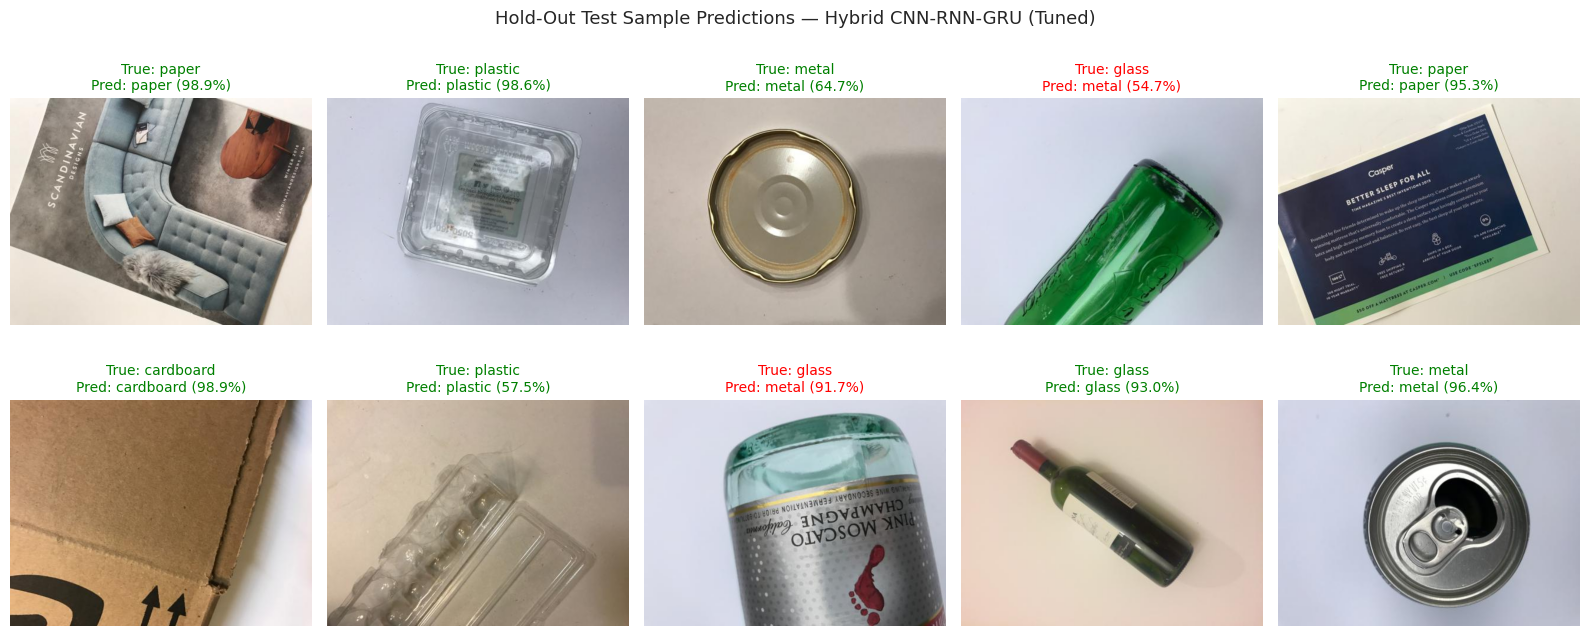

Total Misclassified Test Images: 42 / 253


In [24]:
# Visualize 10 random test predictions (correct and incorrect)
np.random.seed(SEED)
sample_indices = np.random.choice(len(test_df), size=10, replace=False)

plt.figure(figsize=(16, 7))
for i, idx in enumerate(sample_indices):
    img_path = test_df.loc[idx, "image_path"]
    true_lbl = categories[best_test["y_true"][idx]]
    pred_lbl = categories[best_test["y_pred"][idx]]
    conf = np.max(best_test["y_probs"][idx]) * 100

    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    plt.subplot(2, 5, i + 1)
    plt.imshow(img)
    color = "green" if true_lbl == pred_lbl else "red"
    plt.title(f"True: {true_lbl}\nPred: {pred_lbl} ({conf:.1f}%)", color=color, fontsize=10)
    plt.axis("off")

plt.suptitle(f"Hold-Out Test Sample Predictions — {best_model_name}", fontsize=13)
plt.tight_layout()
plt.show()

# Audit top misclassified examples
misclassified_idx = np.where(best_test["y_true"] != best_test["y_pred"])[0]
print(f"Total Misclassified Test Images: {len(misclassified_idx)} / {len(test_df)}")

## 15. Final Model Export and End-to-End Machine Learning Inference Pipeline

Finally, we serialize the selected best-performing model (`final_waste_segregation_cnn_rnn_gru.keras`) and encapsulate the complete preprocessing-to-prediction workflow into a reusable inference function (`predict_waste_category`) ready for real-time sorting or Streamlit deployment.

In [25]:
import json

FINAL_MODEL_PATH = "final_waste_segregation_cnn_rnn_gru.keras"
best_model.save(FINAL_MODEL_PATH)

with open("class_labels.json", "w") as f:
    json.dump(categories, f)

print(f"Saved final model to: {FINAL_MODEL_PATH}")

# Reload model to verify standalone inference pipeline
loaded_model = keras.models.load_model(FINAL_MODEL_PATH)

def predict_waste_category(image_path, model=loaded_model, class_names=categories):
    """
    Complete End-to-End Inference Pipeline:
    1. Reads raw digital image from disk
    2. Converts BGR -> RGB, resizes to 224x224, normalizes to [0, 1]
    3. Runs forward pass through trained Hybrid CNN-RNN-GRU model
    4. Returns predicted waste class, confidence score, class probabilities, and latency
    """
    t0 = time.perf_counter()
    img = cv2.imread(image_path)
    if img is None:
        raise ValueError(f"Could not read image at path: {image_path}")

    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE))
    img_norm = img_resized.astype("float32") / 255.0
    input_tensor = np.expand_dims(img_norm, axis=0)

    probs = model.predict(input_tensor, verbose=0)[0]
    latency_ms = (time.perf_counter() - t0) * 1000.0

    pred_idx = int(np.argmax(probs))
    return {
        "image_path": image_path,
        "predicted_class": class_names[pred_idx],
        "confidence": round(float(probs[pred_idx]) * 100, 2),
        "inference_latency_ms": round(latency_ms, 2),
        "all_probabilities": {class_names[i]: round(float(probs[i]) * 100, 2) for i in range(len(class_names))}
    }

# Test end-to-end pipeline on an unseen test image
demo_sample = test_df.iloc[0]
prediction_output = predict_waste_category(demo_sample["image_path"])
print("\n--- End-to-End Pipeline Inference Demo ---")
print("Ground Truth Category:", demo_sample["category"])
print("Pipeline Output:", json.dumps(prediction_output, indent=2))

Saved final model to: final_waste_segregation_cnn_rnn_gru.keras

--- End-to-End Pipeline Inference Demo ---
Ground Truth Category: trash
Pipeline Output: {
  "image_path": "/content/trashnet_extracted/dataset-resized/trash/trash14.jpg",
  "predicted_class": "cardboard",
  "confidence": 97.59,
  "inference_latency_ms": 1450.45,
  "all_probabilities": {
    "cardboard": 97.59,
    "glass": 0.06,
    "metal": 0.16,
    "paper": 0.9,
    "plastic": 0.16,
    "trash": 1.13
  }
}



---

# 16. Final Conclusion, Project Findings, and Future Work

## 16.1 Final Conclusion

This project successfully implemented an end-to-end Machine Learning pipeline for automated waste classification using deep learning techniques.

Four model configurations were trained and evaluated. The Hybrid CNN-RNN-GRU (Base) achieved the best performance, with 83.79% test accuracy and 84.67% Macro-F1 score.

The experimental results demonstrate that combining CNN-based spatial feature extraction with recurrent layers can improve waste classification performance compared to the baseline CNN.

## 16.2 Final Model Performance

The selected model achieved the following results:

- Test Accuracy: 83.79%
- Macro Precision: 84.77%
- Macro Recall: 84.76%
- Macro-F1 Score: 84.67%

The Hybrid CNN-RNN-GRU (Base) was selected based on its validation Macro-F1 score.

## 16.3 Key Findings

1. The hybrid architecture outperformed the baseline CNN.
2. Hyperparameter tuning did not improve performance over the base hybrid model.
3. Class weighting did not produce better overall Macro-F1 performance.
4. Data augmentation helped introduce variations into training samples.
5. The final model was successfully exported and tested using an end-to-end inference function.

## 16.4 Limitations and Future Work

- Increase the size and diversity of the waste image dataset.
- Explore Vision Transformers and attention-based architectures.
- Apply more advanced hyperparameter optimization techniques.
- Improve classification performance for visually similar waste categories.
- Deploy the trained model through a web-based waste classification application.

## 16.5 Final Project Outcome

The project demonstrates a complete Machine Learning workflow, including data preprocessing, dataset splitting, model development, training, optimization, evaluation, model comparison, visualization, and final model deployment preparation.

**Final Selected Model: Hybrid CNN-RNN-GRU (Base)**

**Final Test Accuracy: 83.79%**

**Final Test Macro-F1: 84.67%**
